# Étape 4 — Tom

In [1]:
import pandas as pd

from load_data import GENRES, load_prepared

df = load_prepared()
df["age_bin"] = pd.cut(
    df["age"],
    bins=[0, 17, 24, 34, 44, 54, 100],
    labels=["≤17", "18-24", "25-34", "35-44", "45-54", "55+"],
)

## 3. Que se passe-t-il ?

Comme dans l'EDA Toyota, on commence par observer les distributions, puis on compare les groupes et on étudie les relations entre variables. Ici, l'objectif est de comprendre les notes de films selon les utilisateurs, les genres et la popularité.

### Distributions

Les notes sont comprises entre 1 et 5. Les indicateurs par utilisateur et par film permettent de distinguer l'activité, la popularité et l'appréciation moyenne.


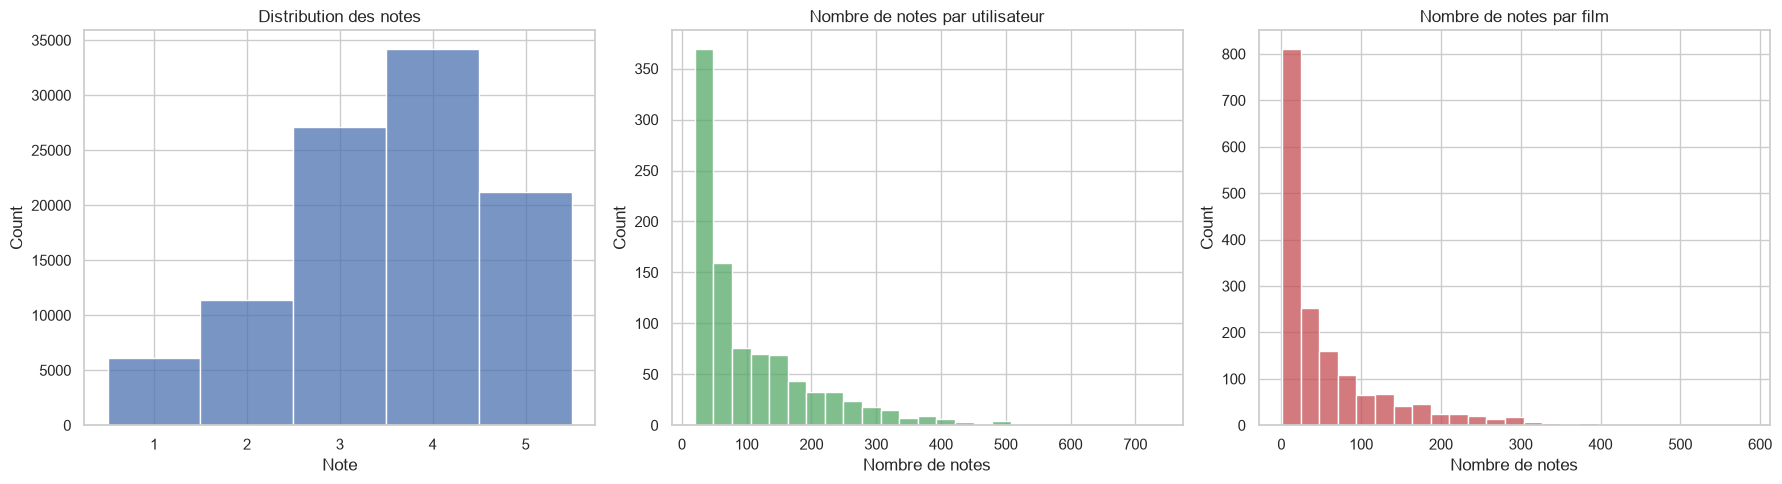

,rating
count,100000.00
mean,3.53
std,1.13
min,1.00
25%,3.00
50%,4.00
75%,4.00
max,5.00


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=df, x="rating", discrete=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution des notes")
axes[0].set_xlabel("Note")

notes_par_user = df.groupby("user_id").size()
sns.histplot(notes_par_user, bins=25, ax=axes[1], color="#55A868")
axes[1].set_title("Nombre de notes par utilisateur")
axes[1].set_xlabel("Nombre de notes")

notes_par_film = df.groupby("item_id").size()
sns.histplot(notes_par_film, bins=25, ax=axes[2], color="#C44E52")
axes[2].set_title("Nombre de notes par film")
axes[2].set_xlabel("Nombre de notes")

plt.tight_layout()
plt.show()

display(df["rating"].describe().round(2).to_frame("rating"))


### Groupes et tendances

Les groupes sont comparés avec leur effectif, leur note moyenne et leur dispersion. Les petits effectifs doivent être interprétés avec prudence.


,n_notes,note_moyenne,note_std
age_bin,,,
≤17,2491,3.424,1.227
18-24,24060,3.474,1.174
25-34,35444,3.488,1.137
35-44,19591,3.588,1.076
45-54,12780,3.627,1.079
55+,5634,3.655,1.036


,n_notes,note_moyenne,note_std
gender,,,
F,25740,3.532,1.171
M,74260,3.529,1.110


,n_notes,note_moyenne,note_std
genre,,,
Film-Noir,1733,3.922,0.993
War,9398,3.816,1.080
Drama,39895,3.687,1.079
Documentary,758,3.673,1.180
Mystery,5245,3.638,1.091
Crime,8055,3.632,1.113
Romance,19461,3.622,1.096
Western,1854,3.613,1.042
Animation,3605,3.577,1.097


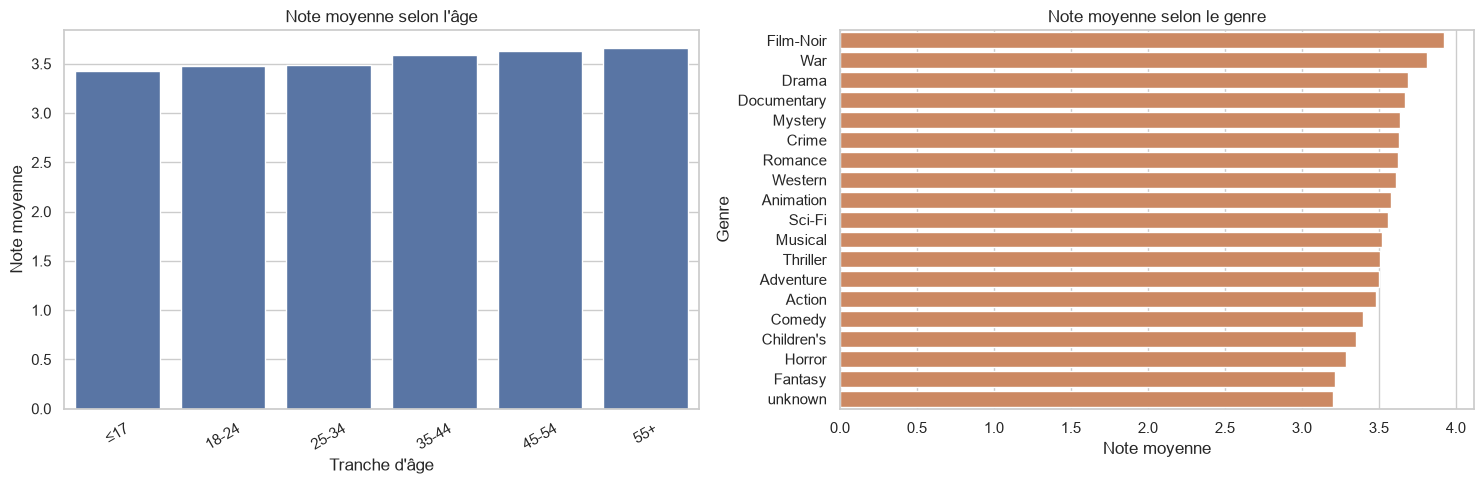

In [3]:
age_summary = (
    df.groupby("age_bin", observed=False)
      .agg(n_notes=("rating", "size"), note_moyenne=("rating", "mean"), note_std=("rating", "std"))
      .round(3)
)

gender_summary = (
    df.groupby("gender")
      .agg(n_notes=("rating", "size"), note_moyenne=("rating", "mean"), note_std=("rating", "std"))
      .round(3)
)

genre_summary = (
    df.melt(id_vars=["rating"], value_vars=GENRES, var_name="genre", value_name="is_genre")
      .query("is_genre == 1")
      .groupby("genre")
      .agg(n_notes=("rating", "size"), note_moyenne=("rating", "mean"), note_std=("rating", "std"))
      .sort_values("note_moyenne", ascending=False)
      .round(3)
)

display(age_summary)
display(gender_summary)
display(genre_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=age_summary.reset_index(), x="age_bin", y="note_moyenne", ax=axes[0], color="#4C72B0")
axes[0].set_title("Note moyenne selon l'âge")
axes[0].set_xlabel("Tranche d'âge")
axes[0].set_ylabel("Note moyenne")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=genre_summary.reset_index(), x="note_moyenne", y="genre", ax=axes[1], color="#DD8452")
axes[1].set_title("Note moyenne selon le genre")
axes[1].set_xlabel("Note moyenne")
axes[1].set_ylabel("Genre")

plt.tight_layout()
plt.show()


### Relations entre variables

La popularité d'un film est mesurée par le nombre de notes. On compare cette popularité à sa note moyenne et à son année de sortie. Une corrélation décrit une association, pas une causalité.


,item_id,title,n_notes,note_moyenne,release_year
49,50,Star Wars (1977),583,4.358,1977.0
257,258,Contact (1997),509,3.804,1997.0
99,100,Fargo (1996),508,4.156,1997.0
180,181,Return of the Jedi (1983),507,4.008,1997.0
293,294,Liar Liar (1997),485,3.157,1997.0
285,286,"English Patient, The (1996)",481,3.657,1996.0
287,288,Scream (1996),478,3.441,1996.0
0,1,Toy Story (1995),452,3.878,1995.0
299,300,Air Force One (1997),431,3.631,1997.0
120,121,Independence Day (ID4) (1996),429,3.438,1996.0


,n_notes,note_moyenne,release_year
n_notes,1.000,0.430,-0.074
note_moyenne,0.430,1.000,-0.238
release_year,-0.074,-0.238,1.000


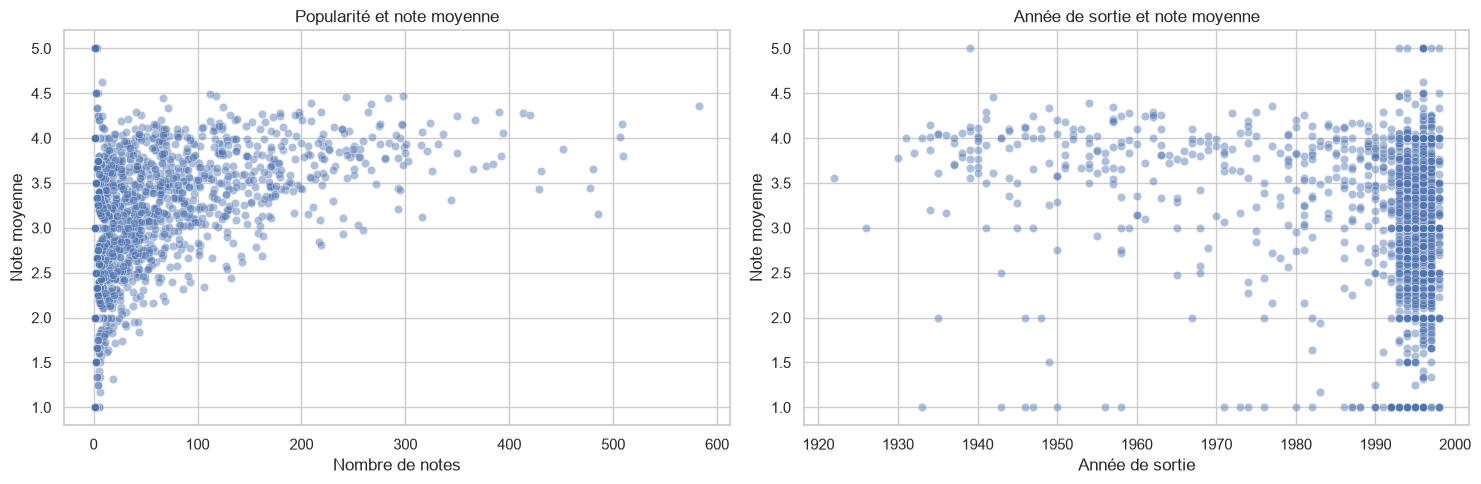

In [4]:
film_summary = (
    df.groupby(["item_id", "title"], as_index=False)
      .agg(n_notes=("rating", "size"), note_moyenne=("rating", "mean"), release_year=("release_year", "first"))
)

display(film_summary.sort_values("n_notes", ascending=False).head(10).round(3))
display(film_summary[["n_notes", "note_moyenne", "release_year"]].corr().round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=film_summary, x="n_notes", y="note_moyenne", alpha=0.45, ax=axes[0])
axes[0].set_title("Popularité et note moyenne")
axes[0].set_xlabel("Nombre de notes")
axes[0].set_ylabel("Note moyenne")

sns.scatterplot(data=film_summary, x="release_year", y="note_moyenne", alpha=0.45, ax=axes[1])
axes[1].set_title("Année de sortie et note moyenne")
axes[1].set_xlabel("Année de sortie")
axes[1].set_ylabel("Note moyenne")

plt.tight_layout()
plt.show()


## 4. Qu'est-ce qui manque ?

L'EDA décrit les tendances observées dans MovieLens 100k, mais elle ne permet pas de généraliser les résultats à toute la population ni d'expliquer les causes.

### Biais

- **Biais de sélection** : les utilisateurs et les films présents dans MovieLens ne représentent pas nécessairement tous les publics ni tout le catalogue.
- **Biais de participation** : nous observons uniquement les notes déposées. Ne pas noter un film ne signifie pas forcément ne pas l'aimer.
- **Biais de popularité** : les films très connus ont davantage de notes et pèsent davantage dans les analyses globales.

### Limites des données

- Le jeu contient des notes, des informations déclarées sur les utilisateurs et des genres, mais pas le contexte de visionnage, les recommandations reçues, les goûts non exprimés ou les raisons d'une note.
- Les données sont historiques et couvrent une période limitée ; les comportements et les films ont évolué depuis.
- Certaines catégories sont peu représentées. Une moyenne calculée sur très peu de notes doit donc être interprétée avec prudence.

### Représentativité

Les résultats décrivent les utilisateurs de ce jeu de données, pas la population générale. Les comparaisons entre groupes doivent tenir compte des effectifs, de l'âge, du sexe, du métier et du nombre de notes par personne.

### Causalité

Une différence de moyenne ou une corrélation ne prouve pas qu'une variable en cause une autre. Par exemple, une association entre l'âge et les notes peut être liée au genre des films vus, à la popularité des films ou à d'autres variables non observées. Il faudrait une étude contrôlée ou une méthode causale adaptée pour conclure à un effet.


In [5]:
print("=== Contrôles pour interpréter l'EDA ===")
print(f"Utilisateurs observés : {df['user_id'].nunique():,}")
print(f"Films observés        : {df['item_id'].nunique():,}")
print(f"Notes observées       : {len(df):,}")

notes_par_film = df.groupby("item_id").size()
print(f"Films avec moins de 10 notes : {(notes_par_film < 10).sum():,}")
print(f"Film le plus noté             : {notes_par_film.max():,} notes")

print("\nConclusion : les résultats sont descriptifs et doivent être interprétés avec prudence.")

=== Contrôles pour interpréter l'EDA ===
Utilisateurs observés : 943
Films observés        : 1,682
Notes observées       : 100,000
Films avec moins de 10 notes : 530
Film le plus noté             : 583 notes

Conclusion : les résultats sont descriptifs et doivent être interprétés avec prudence.
